# RadCalNet-OC products of an AERONET-OC site

This tutorial makes the RadCalNet-OC products of an AERONET-OC site, as delivered to the ESA RadCalNet
project: for every measurement of the station, the top-of-atmosphere (TOA) reflectance simulated at nadir, in
bands of 10 nm every 10 nm from 350 to 2490 nm, with the direct sunglint and its flags; one file per day, and a
copy of the files without the measurements affected by the sunglint.

1. the AERONET-OC database: installation, update, sites;
2. batch processing of one month of a site (AAOT, April 2025);
3. the content of a daily file;
4. the glint-filtered copy;
5. how to process a whole site.

Requirements: the full TOA look-up table ({doc}`../installation`), invRrs 1.4 (from GitHub, see {doc}`../installation`) and
the AERONET-OC database (`aeronet_oc_db`, below). The chain run for each measurement is the one of the tutorial
{doc}`radcalnet_oc_aeronet_oc_quickstart`, at nadir.

In [1]:
import logging
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
rc = {"font.family": "serif",
      "mathtext.fontset": "stix"}
plt.rcParams.update(rc)
plt.rcParams["font.serif"] = ["Times New Roman"] + plt.rcParams["font.serif"]
plt.rcParams.update({'font.size': 16, 'axes.labelsize': 18})
# no warning when the Times New Roman font is not installed
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import xarray as xr

import aeronet_oc_db
import radcalnet_oc as radoc
from radcalnet_oc.aeronet_oc import aeronet_inputs
from radcalnet_oc.products import make_products, glint_ok

print(f'radcalnet_oc {radoc.__version__}, aeronet_oc_db {aeronet_oc_db.__version__}')

radcalnet_oc 1.2.0, aeronet_oc_db 1.2.1


## 1. The AERONET-OC database

The AERONET-OC data are read from a local copy of the AERONET-OC database, managed by the package
[aeronet_oc_db](https://pypi.org/project/aeronet-oc-db/) (PyPI: `aeronet-oc-db`, source on [GitHub](https://github.com/Tristanovsk/aeronet_oc_db)): it downloads the data of all the sites from the
AERONET web service and converts them into one netCDF file per site and level (with the remote-sensing
reflectance `Rrs_Lwn` computed from the normalized water-leaving radiance).

**Installation**

```bash
pip install "git+https://github.com/Tristanovsk/invRrs.git@v1.4.0"
pip install "radcalnet_oc[invrrs,aeronet]"     # also installs aeronet-oc-db from PyPI
```

**Location of the database**: the environment variable `AERONET_OC_ROOT`, or the file
`~/.config/aeronet_oc_db/config.toml` (also read by Jupyter and cron jobs, which do not always inherit the
shell environment):

```toml
root = "/path/to/AERONET/OCv3"
```

**Download and update** (command line):

```bash
aeronet-oc-db update --discover                     # first time: all the sites (full download), then monthly
aeronet-oc-db update --days 30                      # quick update: the last 30 days
aeronet-oc-db update --sites AAOT --levels lev20    # one site and level
aeronet-oc-db status                                # catalog of the database
```

Level 2.0 data (quality assured) are published months after the measurements and past data are reprocessed:
run a full update from time to time. Level 1.5 data are available in near real time.

The catalog lists the sites, their level, number of records and period:

In [2]:
catalog = aeronet_oc_db.catalog()
lev20 = catalog[catalog.level == 'lev20'].sort_values('n_records', ascending=False)
print(f"{catalog.site.nunique()} sites, {len(lev20)} with level 2.0 data")
lev20[['site', 'n_records', 'start', 'end', 'latitude', 'longitude', 's2_tile']].head(10).set_index('site')

43 sites, 41 with level 2.0 data


,n_records,start,end,latitude,longitude,s2_tile
site,,,,,,
AAOT,22520,2017-10-23 09:38:09,2025-07-16 12:30:29,45.313900,12.508300,32TQR
Venise,11421,2002-04-20 11:16:16,2023-03-12 14:52:15,45.313900,12.508300,32TQR
Chesapeake_Bay,10298,2021-10-07 13:25:38,2025-07-08 19:54:43,39.123510,-76.348900,18SUJ
Section-7_Platform,10240,2019-08-27 05:10:49,2024-08-18 12:36:00,44.545800,29.446600,35TPK
Casablanca_Platform,10104,2019-04-02 13:43:52,2024-06-30 13:17:25,40.717000,1.358000,31TCF
Galata_Platform,9531,2014-04-14 06:39:20,2023-12-19 08:42:38,43.044624,28.193190,35TNH
USC_SEAPRISM,8020,2012-02-09 18:19:48,2025-01-15 21:45:50,33.563710,-118.117820,11SLT
Gustav_Dalen_Tower,6427,2005-06-12 11:23:42,2024-09-19 07:29:28,58.594170,17.466830,33VXF
Gloria,5253,2011-01-25 09:49:25,2019-08-07 08:47:26,44.599970,29.359670,35TPK


The data of a site are an {py:class}`xarray.Dataset` (dimensions `time` and `wl`, the bands of the
radiometer):

In [3]:
with aeronet_oc_db.open_site('AAOT', 'lev20') as ds:
    aaot = ds[['Rrs_Lwn', 'aot', 'sza', 'wind', 'chl']].drop_attrs().load()
aaot

<xarray.Dataset> Size: 2MB
Dimensions:    (time: 22520, wl: 11)
Coordinates:
  * time       (time) datetime64[ns] 180kB 2017-10-23T09:38:09 ... 2025-07-16...
  * wl         (wl) float64 88B 400.0 412.0 443.0 490.0 ... 779.0 865.0 1.02e+03
    latitude   float64 8B 45.31
    longitude  float64 8B 12.51
    elevation  float64 8B 10.0
Data variables:
    Rrs_Lwn    (time, wl) float32 991kB 0.002447 0.002754 ... -4.522e-06
    aot        (time, wl) float32 991kB 0.04987 0.04809 ... 0.1578 0.1282
    sza        (time) float32 90kB 59.28 57.34 67.62 65.42 ... 25.25 25.58 28.62
    wind       (time) float32 90kB 7.366 7.319 7.258 7.317 ... 1.921 1.938 2.198
    chl        (time) float32 90kB 1.544 1.543 1.53 1.505 ... 1.878 1.87 2.389

{py:func}`~radcalnet_oc.aeronet_oc.aeronet_inputs` converts them into the inputs of the simulation (gas
columns in kg m$^{-2}$, AOT at 550 and 865 nm, spectral AOT normalized at 550 nm `naot`, `Rrs_Lwn`, chlorophyll
and solar zenith angle), for a period:

In [4]:
inputs = aeronet_inputs('AAOT', 'lev20', start='2025-04-01', end='2025-04-30')
print(f"{inputs.sizes['time']} measurements in April 2025")
inputs

196 measurements in April 2025


<xarray.Dataset> Size: 38kB
Dimensions:      (time: 196, wl: 11, wl_aeronet: 11)
Coordinates:
  * time         (time) datetime64[ns] 2kB 2025-04-02T09:32:29 ... 2025-04-30...
  * wl           (wl) float64 88B 400.0 412.0 443.0 ... 779.0 865.0 1.02e+03
  * wl_aeronet   (wl_aeronet) float64 88B 400.0 412.0 443.0 ... 865.0 1.02e+03
Data variables:
    tcwv         (time) float32 784B 14.6 14.64 14.56 14.46 ... 9.599 9.627 9.67
    tco3         (time) float32 784B 0.007964 0.007964 ... 0.00792 0.00792
    tcno2        (time) float32 784B 6.871e-06 6.87e-06 ... 6.152e-06 6.152e-06
    pressure     (time) float32 784B 1.016e+03 1.016e+03 ... 1.019e+03 1.019e+03
    wind         (time) float32 784B 6.168 6.091 5.859 ... 1.533 1.42 1.413
    aot550       (time) float64 2kB 0.1083 0.1086 0.1075 ... 0.05451 0.05462
    aot865       (time) float64 2kB 0.06535 0.06536 0.06633 ... 0.03212 0.03213
    ang_exp      (time) float64 2kB 1.115 1.122 1.067 ... 1.123 1.168 1.172
    naot         (time, wl_aeronet) float64 17kB 1.413 1.374 ... 0.5882 0.4714
    chl          (time) float32 784B 3.472 4.872 3.369 ... 2.009 1.876 2.019
    sza_aeronet  (time) float32 784B 45.69 43.84 40.46 ... 31.84 36.98 37.57
    Rrs_Lwn      (time, wl) float32 9kB 0.002109 0.002287 ... -2.676e-05

## 2. Batch processing of one month

{py:func}`~radcalnet_oc.products.make_products` runs the whole chain for a site and a period, month by month.
For every measurement: hyperspectral $R_{rs}$ reconstructed with invRrs, aerosol model mixture retrieved from the
spectral AOT, simulation at nadir with the direct sunglint at the wind speed of the station, then convolution with
bands of 10 nm. The full-spectral simulation of each month is kept in a cache folder (`<odir>/monthly` by default,
argument `cache`), and the daily files are written in `odir`.

The command line `radcalnet_oc-products` does the same, with the same options:

```bash
radcalnet_oc-products --site AAOT --level lev20 --name VEIT --start 2025-04-01 --end 2025-04-30 --odir radcalnet_oc_products
```

`name` is the name of the site in the products (here the RadCalNet code of AAOT, VEIT). Change `odir` to the
folder of your products.

In [5]:
# folder of the products: change it (the environment variable RADCALNET_OC_PRODUCTS, if set, overrides it)
odir = Path(os.environ.get('RADCALNET_OC_PRODUCTS', 'radcalnet_oc_products'))

radoc.set_logging('WARNING')                                    # warnings of the package
logging.getLogger('radcalnet_oc.products').setLevel('INFO')     # progress of the batch processing

t0 = time.time()
summary = make_products('AAOT', 'lev20', name='VEIT', start='2025-04-01', end='2025-04-30', odir=odir)
elapsed = time.time() - t0
print(summary, f'{elapsed:.0f} s')

2026-11-23 22:39:31,607 INFO radcalnet_oc.products | AAOT lev20: 196 measurements 2025-04-02 - 2025-04-30


2026-11-23 22:40:52,684 INFO radcalnet_oc.products | 2025-04: 196 times (80 s)


2026-11-23 22:40:52,867 WARNING radcalnet_oc.lut | spectral response of the band(s) at [ 350.  360. 2490.] nm truncated by the wavelength range of the signal (350.109-2499.69 nm)


2026-11-23 22:40:54,446 INFO radcalnet_oc.products | done: 12 days, 196 times, 101 kept after the glint filter (81 s)


{'months': 1, 'days': 12, 'times': 196, 'kept': 101, 'failed': []} 83 s


The warning is expected: the first two bands and the last one are slightly truncated by the range of the
simulation (350.1-2499.7 nm).

A second run reads the month from the cache and keeps the daily files already written: an interrupted run
restarts where it stopped. `overwrite=True` (`--overwrite`) recomputes the months and rewrites the files.

In [6]:
t0 = time.time()
make_products('AAOT', 'lev20', name='VEIT', start='2025-04-01', end='2025-04-30', odir=odir)
print(f'{time.time() - t0:.1f} s')

2026-11-23 22:40:54,832 INFO radcalnet_oc.products | AAOT lev20: 196 measurements 2025-04-02 - 2025-04-30


2026-11-23 22:40:55,066 WARNING radcalnet_oc.lut | spectral response of the band(s) at [ 350.  360. 2490.] nm truncated by the wavelength range of the signal (350.109-2499.69 nm)


2026-11-23 22:40:55,599 INFO radcalnet_oc.products | done: 12 days, 196 times, 101 kept after the glint filter (1 s)


1.1 s


## 3. The daily files

The products are organized by site, year, month and day:

```
<odir>/daily/<site>/<yyyy>/<mm>/<dd>/<site>_radcalnet-oc_<level>_<yyyymmdd>_inc10nm_res10nm.nc
<odir>/daily_glint_filtered/<site>/<yyyy>/<mm>/<dd>/<site>_radcalnet-oc_<level>_<yyyymmdd>_inc10nm_res10nm.nc
<odir>/monthly/<site>/<site>_radcalnet-oc_<level>_<yyyy>_<mm>_full_spectral.nc
```

In [7]:
files = sorted(odir.rglob('*.nc'))
for f in files[:4] + files[-4:]:
    print(f'{f.relative_to(odir)}  ({f.stat().st_size / 1e6:.2f} MB)')
print(f'... {len(files)} files')

daily/VEIT/2025/04/02/VEIT_radcalnet-oc_lev20_20250402_inc10nm_res10nm.nc  (0.10 MB)
daily/VEIT/2025/04/03/VEIT_radcalnet-oc_lev20_20250403_inc10nm_res10nm.nc  (0.21 MB)
daily/VEIT/2025/04/04/VEIT_radcalnet-oc_lev20_20250404_inc10nm_res10nm.nc  (0.27 MB)
daily/VEIT/2025/04/05/VEIT_radcalnet-oc_lev20_20250405_inc10nm_res10nm.nc  (0.23 MB)
daily_glint_filtered/VEIT/2025/04/08/VEIT_radcalnet-oc_lev20_20250408_inc10nm_res10nm.nc  (0.26 MB)
daily_glint_filtered/VEIT/2025/04/09/VEIT_radcalnet-oc_lev20_20250409_inc10nm_res10nm.nc  (0.08 MB)
daily_glint_filtered/VEIT/2025/04/11/VEIT_radcalnet-oc_lev20_20250411_inc10nm_res10nm.nc  (0.08 MB)
monthly/VEIT/VEIT_radcalnet-oc_lev20_2025_04_full_spectral.nc  (274.58 MB)
... 21 files


In [8]:
with xr.open_dataset(odir / 'daily/VEIT/2025/04/05/VEIT_radcalnet-oc_lev20_20250405_inc10nm_res10nm.nc') as f:
    day = f.load()
day

<xarray.Dataset> Size: 189kB
Dimensions:              (time: 23, wl: 215, model: 6)
Coordinates:
  * time                 (time) datetime64[ns] 184B 2025-04-05T08:49:46 ... 2...
    aot_ref              (time) float64 184B 0.1953 0.1958 ... 0.2147 0.2115
    sza                  (time) float32 92B 49.67 49.04 44.79 ... 49.2 49.83
  * wl                   (wl) float64 2kB 350.0 360.0 ... 2.48e+03 2.49e+03
  * model                (model) <U9 216B 'ARCT_rh70' 'COAV_rh70' ... 'WASO_rh0'
    vza                  float64 8B 0.0
Data variables: (12/29)
    Ed                   (time, wl) float32 20kB 425.6 413.3 ... 6.905 1.317
    Ratm                 (time, wl) float32 20kB 0.2674 0.2506 ... 2.209e-05
    Rrs                  (time, wl) float64 40kB nan 0.002218 ... 2.937e-08
    bbp_nir              (time) float64 184B 0.007649 0.007772 ... 0.006393
    E0                   (time, wl) float32 20kB 673.0 639.5 ... 33.32 32.92
    Rtoa                 (time, wl) float32 20kB 0.2704 0.2539 ... 2.209e-05
    ...                   ...
    glint_unc_wl         (time) float64 184B 2.365e+03 2.365e+03 ... 2.367e+03
    glint_flags          (time) uint8 23B 1 1 1 3 3 3 3 3 3 ... 1 1 1 1 1 1 1 1
    chl_invrrs           (time) float64 184B 10.25 10.34 9.681 ... 6.417 6.47
    rmsd_invrrs          (time) float64 184B 6.699e-05 7.906e-05 ... 7.183e-05
    spm_norm_invrrs      (time) float64 184B 0.1949 0.1775 ... 0.1784 0.2237
    glint_uncertain      (time, wl) uint8 5kB 0 0 0 0 0 0 0 0 ... 1 1 1 1 1 1 1
Attributes: (12/25)
    radcalnet_oc_version:  1.2.0+ge40cb2b
    o2_model:              lbl
    gas_coupling:          path_length
    gas_coupling_table:    gas_coupling_ppld.csv
    rrs_extension:         pure_water
    rayleigh_pressure:     1
    ...                    ...
    invrrs_max_sza:        80.0
    invrrs_min_bands:      5
    site:                  VEIT
    aeronet_oc_site:       AAOT
    aeronet_oc_level:      lev20
    geometry:              nadir view

Each file has the dimensions `time` (measurements of the day), `wl` (10 nm bands) and `model` (aerosol
models). The variables, with their unit and description:

In [9]:
pd.DataFrame([{'variable': name, 'dimensions': ', '.join(v.dims), 'unit': v.attrs.get('unit', v.attrs.get('units', '')),
               'description': v.attrs.get('description', v.attrs.get('long_name', ''))}
              for name, v in day.data_vars.items()]).set_index('variable')

,dimensions,unit,description
variable,,,
Ed,"time, wl",mW m-2 nm-1,Plane solar irradiance at bottom-of-atmosphere
Ratm,"time, wl",-,Atmosphere (intrinsic + surface reflected) ref...
Rrs,"time, wl",sr-1,Remote sensing reflectance
bbp_nir,time,m-1,particulate backscattering coefficient fitted ...
E0,"time, wl",mW m-2 nm-1,Plane solar irradiance at top-of-atmosphere
Rtoa,"time, wl",-,Total reflectance at top-of-atmosphere
tcwv,time,kg m-2,total column water vapour
tco3,time,kg m-2,total column ozone
tcno2,time,kg m-2,total column NO2


The main ones:

- `Rtoa`: TOA reflectance at nadir **without** the direct sunglint; `Rglint`: the direct sunglint at the TOA;
  `Rtoa_glint = Rtoa + Rglint`, what the satellite sees; `Rglint_unc`: uncertainty of the sunglint (range of
  plausible sea-surface slope statistics, wind ± 1.5 m s$^{-1}$);
- `glint_flags`: bitmask of the sunglint level (`radcalnet_oc.GLINT_FLAGS`): low, moderate, high (sunglint above
  1, 10, 50 % of the TOA reflectance at 865 nm) and near specular (glint angle below 30°);
  `glint_fraction`, `glint_angle`: the sunglint fraction at 865 nm and the glint angle;
- `glint_uncertain`: per band, 1 where the uncertainty of the sunglint exceeds 5 % of the TOA reflectance;
- the irradiances `Ed` (surface) and `E0` (TOA), the water reflectance `Rrs` used, the inputs (AOT, Angström
  exponent, gas columns, pressure, wind, solar zenith angle), the aerosol mixture `aerosol_combination` and the
  outputs of invRrs (`chl_invrrs`, `rmsd_invrrs`...).

The flags of the measurements of the day (5 April 2025):

In [10]:
def flag_names(value):
    return ', '.join(name.replace('glint_', '') for name, bit in radoc.GLINT_FLAGS.items() if int(value) & bit)


pd.DataFrame({'glint angle': day.glint_angle.values.round(1),
              'glint fraction at 865 nm': day.glint_fraction.values.round(3),
              'glint_flags': day.glint_flags.to_pandas().map(flag_names).values,
              'bands glint_uncertain (400-900 nm)': day.glint_uncertain.sel(wl=slice(400, 900)).sum('wl').values},
             index=day.time.to_index().strftime('%H:%M'))

,glint angle,glint fraction at 865 nm,glint_flags,bands glint_uncertain (400-900 nm)
time,,,,
08:49,49.7,0.033,low,0
08:54,49.0,0.034,low,0
09:30,44.8,0.052,low,2
10:30,40.1,0.102,"low, moderate",18
10:35,39.8,0.106,"low, moderate",19
10:39,39.6,0.109,"low, moderate",20
10:49,39.3,0.116,"low, moderate",21
10:54,39.2,0.118,"low, moderate",21
10:58,39.1,0.120,"low, moderate",21


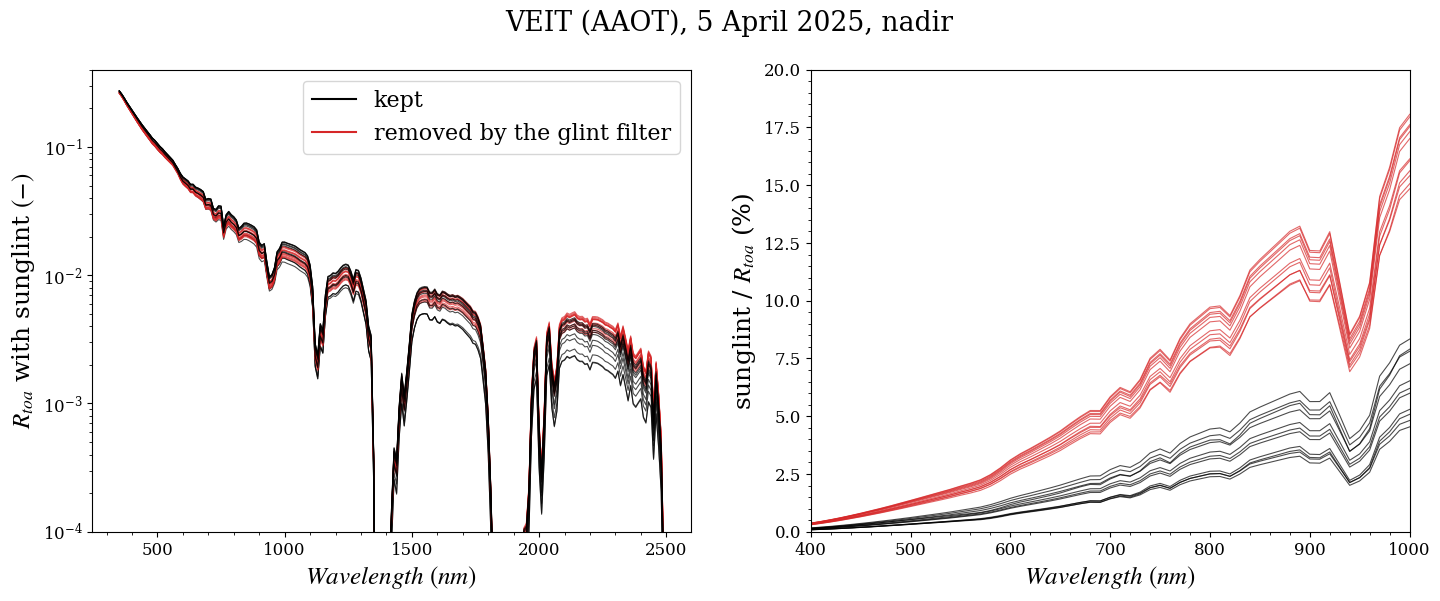

In [11]:
removed = ~glint_ok(day)       # flags removed from the glint-filtered copy (moderate, near specular)
fig, axs = plt.subplots(1, 2, figsize=(17, 6))
for it in range(day.sizes['time']):
    d = day.isel(time=it)
    color = 'tab:red' if removed[it] else 'k'
    d.Rtoa_glint.plot(ax=axs[0], color=color, lw=0.8, alpha=0.7)
    (100 * d.Rglint / d.Rtoa_glint).plot(ax=axs[1], color=color, lw=0.8, alpha=0.7)
axs[0].plot([], [], color='k', label='kept')
axs[0].plot([], [], color='tab:red', label='removed by the glint filter')
axs[0].legend()
axs[0].set_yscale('log')
axs[0].set_ylim(1e-4, 0.4)
axs[0].set_ylabel(r'$R_{toa}$ with sunglint $(-)$')
axs[1].set_ylabel(r'sunglint / $R_{toa}$ (%)')
axs[1].set_xlim(400, 1000)
axs[1].set_ylim(0, 20)
for ax in axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_title('')
    ax.minorticks_on()
fig.suptitle('VEIT (AAOT), 5 April 2025, nadir')
plt.show()

At nadir, the glint angle is the solar zenith angle. Around noon the Sun is higher, the glint angle smaller and
the sunglint reaches more than 10 % of the TOA reflectance at 865 nm (moderate level): these measurements are
removed from the filtered copy.

The attributes record the provenance of the simulation: versions of radcalnet_oc and invRrs, options of the
simulation, look-up table, site and AERONET-OC level:

In [12]:
pd.Series(day.attrs)

radcalnet_oc_version             1.2.0+ge40cb2b
o2_model                                    lbl
gas_coupling                        path_length
gas_coupling_table        gas_coupling_ppld.csv
rrs_extension                        pure_water
rayleigh_pressure                             1
solar_database                             tsis
default_wind                                2.0
toa_lut                 toa_lut_opac_wind_v3.nc
toa_lut_doi             10.5281/zenodo.23394202
invrrs_version                   1.4.0+g3b12a36
invrrs_model                           TwoModes
invrrs_ni_shape                     atd_ext:0.5
invrrs_phyto_model              Ciotti2002_Sf03
invrrs_fluorescence                        none
invrrs_sigma                               none
invrrs_max_nfev                             100
invrrs_vza                                 40.0
invrrs_azi                                 90.0
invrrs_max_sza                             80.0
invrrs_min_bands                        

## 4. The glint-filtered copy

`daily_glint_filtered` holds the same files without the measurements flagged `glint_moderate` or
`glint_near_specular` (option `filter_flags`, `--filter-flags`); the days with no measurement left have no file.
With `filter_uncertain=True` (`--filter-uncertain`), the measurements with `glint_uncertain` in 400-900 nm are
also removed: at nadir, this removes most of the summer measurements of a platform. Number of measurements per
day, all and kept:

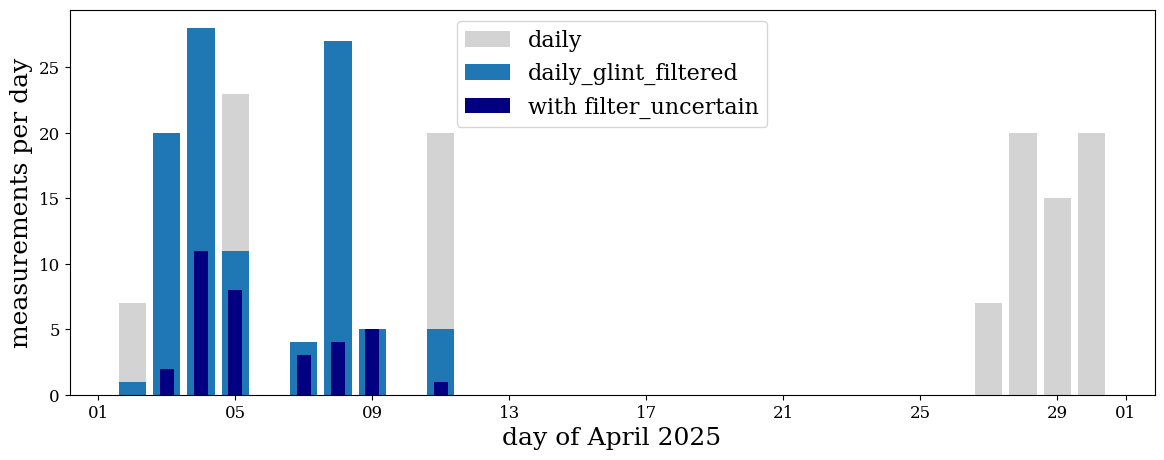

all                          196
kept                         101
strict (filter_uncertain)     34
dtype: int64

In [13]:
rows = []
for f in sorted((odir / 'daily/VEIT').rglob('*.nc')):
    filtered = Path(str(f).replace('/daily/', '/daily_glint_filtered/'))
    with xr.open_dataset(f) as d:
        n_kept = 0
        if filtered.exists():
            with xr.open_dataset(filtered) as d_filtered:
                n_kept = d_filtered.sizes['time']
        rows.append({'day': pd.Timestamp(d.time.values[0]).normalize(), 'all': d.sizes['time'], 'kept': n_kept,
                     'strict (filter_uncertain)': int(glint_ok(d, uncertain=True).sum())})
counts = pd.DataFrame(rows).set_index('day')

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(counts.index, counts['all'], color='lightgrey', label='daily')
ax.bar(counts.index, counts['kept'], color='tab:blue', label='daily_glint_filtered')
ax.bar(counts.index, counts['strict (filter_uncertain)'], color='navy', width=0.4, label='with filter_uncertain')
ax.set_ylabel('measurements per day')
ax.set_xlabel('day of April 2025')
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%d'))
ax.legend(loc='upper center')
plt.show()
counts.sum()

At the end of the month, the Sun is high enough for a moderate sunglint at nadir all day long: no
measurement is kept.

Other selections can be made from the `daily` files with {py:func}`~radcalnet_oc.products.glint_ok`, e.g.
`day.isel(time=glint_ok(day, ['glint_high', 'glint_near_specular']).values)` keeps the measurements with low and
moderate sunglint.

## 5. A whole site

The whole record of a site is processed with one command, from the first date of the products (2017) by
default:

```bash
radcalnet_oc-products --site AAOT --level lev20 --name VEIT --odir /path/to/products
radcalnet_oc-products --site Section-7_Platform --level lev15 --name CORO --start 2024-08-19 --odir /path/to/products
```

- **time**: about the time of the month above per month of data, one process (the run of this tutorial gives
  an estimate below);
- **memory**: about 2 GB for the largest months; `--max-times` (default 400) sets the number of
  measurements simulated at once, lower it on a machine with little memory;
- **restart**: an interrupted run restarts from the monthly cache; the months already simulated are only
  convolved and written again where the daily files are missing;
- **update with new AERONET-OC data**: the cached months are not simulated again, so after an update of the
  database rerun the months concerned with `--overwrite` (e.g. `--start 2025-06-01 --overwrite`), or delete their
  monthly files from the cache;
- **other glint filters**: rerun with `--filter-flags ...` or `--filter-uncertain` in another `--odir` with the
  same `--cache`: only the daily files are written again.

Estimate for the level 2.0 record of AAOT, from the run time of the month above:

In [14]:
record = aeronet_inputs('AAOT', 'lev20')
n_months = record.time.dt.strftime('%Y-%m').to_index().nunique()
print(f"{record.sizes['time']} measurements in {n_months} months: "
      f"about {elapsed / inputs.sizes['time'] * record.sizes['time'] / 60:.0f} min")

22520 measurements in 94 months: about 159 min
